In [1]:
# =============================================================================
# SCTEC
# Curso: Integração de IA com Dados
# Professor: Felipe Rodrigues Souza
# Aluno: Anderson Roza
# =============================================================================

# **Gêmeo Digital de Ocupação**
## Pipeline preditivo de ocupação de ambientes para automação predial

**Problema.** Um complexo industrial com sensores IoT precisa saber, em tempo real, se cada sala técnica ou escritório está ocupado (`Occupancy = 1`) ou vazio (`Occupancy = 0`), para desligar sozinho o ar-condicionado (HVAC) e a iluminação das salas vazias e reduzir o custo de energia.

**Base.** Occupancy Detection Dataset (UCI): leituras por minuto de temperatura, umidade, luminosidade, CO₂ e razão de umidade de uma sala de escritório, com o registro real de presença.

**Organização do notebook**

| Fase | Conteúdo |
|---|---|
| 1 | Análise exploratória (EDA) |
| 2 | Limpeza e tratamento dos dados |
| 3 | Feature engineering |
| 4 | Divisão em treino e teste |
| 5 | Escalonamento com StandardScaler |
| 6 | Ajuste de hiperparâmetros e combate ao overfitting |
| 7 | Avaliação da acurácia e veredito final |

# **Base de Dados**

In [2]:
# -----------------------------------------------------------------------------
# Bibliotecas (sugestões do enunciado)
# -----------------------------------------------------------------------------
# os, zipfile e urllib.request: criar pastas, baixar e descompactar a base da UCI
import os
import zipfile
import urllib.request

# pandas: tabelas (DataFrame); numpy: cálculo numérico vetorizado
import pandas as pd
import numpy as np

# matplotlib e seaborn: gráficos da análise exploratória e da avaliação
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn: divisão treino/teste, o modelo de Árvore de Decisão e as métricas
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configurações visuais para os gráficos: fundo com grade leve e tamanho padrão
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Criando a pasta /data conforme boas práticas de caminhos relativos do projeto.
# exist_ok=True evita erro se a pasta já existir (o notebook pode ser rodado várias vezes).
os.makedirs("data", exist_ok=True)
caminho_csv = "data/occupancy.csv"


In [3]:
# -----------------------------------------------------------------------------
# Importações complementares usadas nas Fases 5, 6 e 7
# -----------------------------------------------------------------------------
# StandardScaler: padronização das variáveis para o KNN (média 0 e desvio 1)
from sklearn.preprocessing import StandardScaler

# KNeighborsClassifier: o segundo modelo do projeto, que decide pelos vizinhos mais próximos
from sklearn.neighbors import KNeighborsClassifier

# Validação cruzada: escolhe hiperparâmetros usando só o treino, sem olhar o teste
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

# Métricas complementares e o desenho da árvore
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import plot_tree

In [4]:
# -----------------------------------------------------------------------------
# Download e carga da base (Occupancy Detection Dataset, UCI)
# -----------------------------------------------------------------------------
# Baixando o dataset oficial da UCI se ainda não estiver na pasta /data.
# O teste com os.path.exists garante que o download aconteça só na primeira execução.
if not os.path.exists(caminho_csv):
    url_uci = "https://archive.ics.uci.edu/ml/machine-learning-databases/00357/occupancy_data.zip"
    zip_path = "data/occupancy_data.zip"
    urllib.request.urlretrieve(url_uci, zip_path)

    # O zip traz 3 arquivos (datatraining, datatest e datatest2); extraímos todos em data/raw
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall("data/raw")

    # A atividade usa o datatest.txt (2.665 leituras). Ele é salvo como CSV de trabalho.
    df_temp = pd.read_csv("data/raw/datatest.txt")
    df_temp.to_csv(caminho_csv, index=False)

# Carregamento via caminho relativo: funciona em qualquer máquina, sem caminho fixo
df = pd.read_csv(caminho_csv)
print("Base de dados carregada com sucesso!")

Base de dados carregada com sucesso!


In [5]:
# Print base de dados: exibe as primeiras e as últimas linhas para conferir a carga
df

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.700000,26.272000,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.718000,26.290000,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.730000,26.230000,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.722500,26.125000,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.754000,26.200000,488.600000,779.000000,0.004767,1
...,...,...,...,...,...,...,...
2660,2015-02-04 10:38:59,24.290000,25.700000,808.000000,1150.250000,0.004829,1
2661,2015-02-04 10:40:00,24.330000,25.736000,809.800000,1129.200000,0.004848,1
2662,2015-02-04 10:40:59,24.330000,25.700000,817.000000,1125.800000,0.004841,1
2663,2015-02-04 10:41:59,24.356667,25.700000,813.000000,1123.000000,0.004849,1


<br>

# **Fase 1: Análise Exploratória (EDA)**

> Dimensões, tipos de dados, resumo estatístico, gráficos analíticos e a interpretação dos padrões que orientam a modelagem.

In [6]:
# -----------------------------------------------------------------------------
# Fase 1.1: dimensões e tipos de dados
# -----------------------------------------------------------------------------
# shape devolve (linhas, colunas): é o primeiro retrato do tamanho da base
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
print()

# info() mostra, por coluna, o tipo e a quantidade de valores não nulos.
# Se "Non-Null Count" for menor que o total de linhas, há dados ausentes.
df.info()

Linhas: 2665 | Colunas: 7

<class 'pandas.DataFrame'>
RangeIndex: 2665 entries, 0 to 2664
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           2665 non-null   str    
 1   Temperature    2665 non-null   float64
 2   Humidity       2665 non-null   float64
 3   Light          2665 non-null   float64
 4   CO2            2665 non-null   float64
 5   HumidityRatio  2665 non-null   float64
 6   Occupancy      2665 non-null   int64  
dtypes: float64(5), int64(1), str(1)
memory usage: 145.9 KB


In [7]:
# dtypes resume o tipo de cada coluna: float64 (decimal), int64 (inteiro) ou texto.
# Modelos do scikit-learn só aceitam números, então qualquer coluna de texto
# precisa ser convertida ou descartada antes da modelagem.
df.dtypes

date                 str
Temperature      float64
Humidity         float64
Light            float64
CO2              float64
HumidityRatio    float64
Occupancy          int64
dtype: object

In [8]:
# describe() traz o resumo estatístico das colunas numéricas:
# contagem, média, desvio padrão, mínimo, quartis (25%, 50% = mediana, 75%) e máximo.
# Comparar média e mediana já indica assimetria: se forem muito diferentes,
# a distribuição tem cauda longa (o caso da luminosidade).
df.describe().round(4)

,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,2665.0000,2665.0000,2665.0000,2665.0000,2665.0000,2665.0000
mean,21.4339,25.3539,193.2276,717.9065,0.0040,0.3647
std,1.0280,2.4368,250.2109,292.6817,0.0006,0.4814
min,20.2000,22.1000,0.0000,427.5000,0.0033,0.0000
25%,20.6500,23.2600,0.0000,466.0000,0.0035,0.0000
50%,20.8900,25.0000,0.0000,580.5000,0.0038,0.0000
75%,22.3567,26.8567,442.5000,956.3333,0.0045,1.0000
max,24.4083,31.4725,1697.2500,1402.2500,0.0054,1.0000


### Coluna `date`

A base carregada traz a coluna `date` (texto no formato `AAAA-MM-DD HH:MM:SS`), com leituras a cada minuto entre 02/02/2015 e 04/02/2015. Ela é útil para entender o contexto (dia e hora), mas não é uma medida física do ambiente: usar o horário como preditor faria o modelo decorar a agenda daquela sala específica, e não aprender o que os sensores dizem sobre presença. Por isso ela é **descartada antes da modelagem**, e o modelo passa a depender apenas das 5 variáveis ambientais.

In [9]:
# -----------------------------------------------------------------------------
# Fase 1.2: avaliação e descarte da coluna date
# -----------------------------------------------------------------------------
# Converte o texto em data/hora de verdade para conferir o período coberto pela base
df["date"] = pd.to_datetime(df["date"])
print("Período:", df["date"].min(), "até", df["date"].max())

# A data não é uma medida do ambiente: se entrasse no modelo, ele aprenderia a agenda
# desta sala (ex.: "às 10h tem gente") em vez de aprender a ler os sensores.
df = df.drop(columns=["date"])

# Constantes usadas em todo o notebook: as 5 variáveis preditoras e a variável alvo
FEATURES = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]
ALVO = "Occupancy"
df.head()

Período: 2015-02-02 14:19:00 até 2015-02-04 10:43:00


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,23.7000,26.272,585.200000,749.200000,0.004764,1
1,23.7180,26.290,578.400000,760.400000,0.004773,1
2,23.7300,26.230,572.666667,769.666667,0.004765,1
3,23.7225,26.125,493.750000,774.750000,0.004744,1
4,23.7540,26.200,488.600000,779.000000,0.004767,1


### Gráfico 1: distribuição de cada variável preditora, separada pela classe

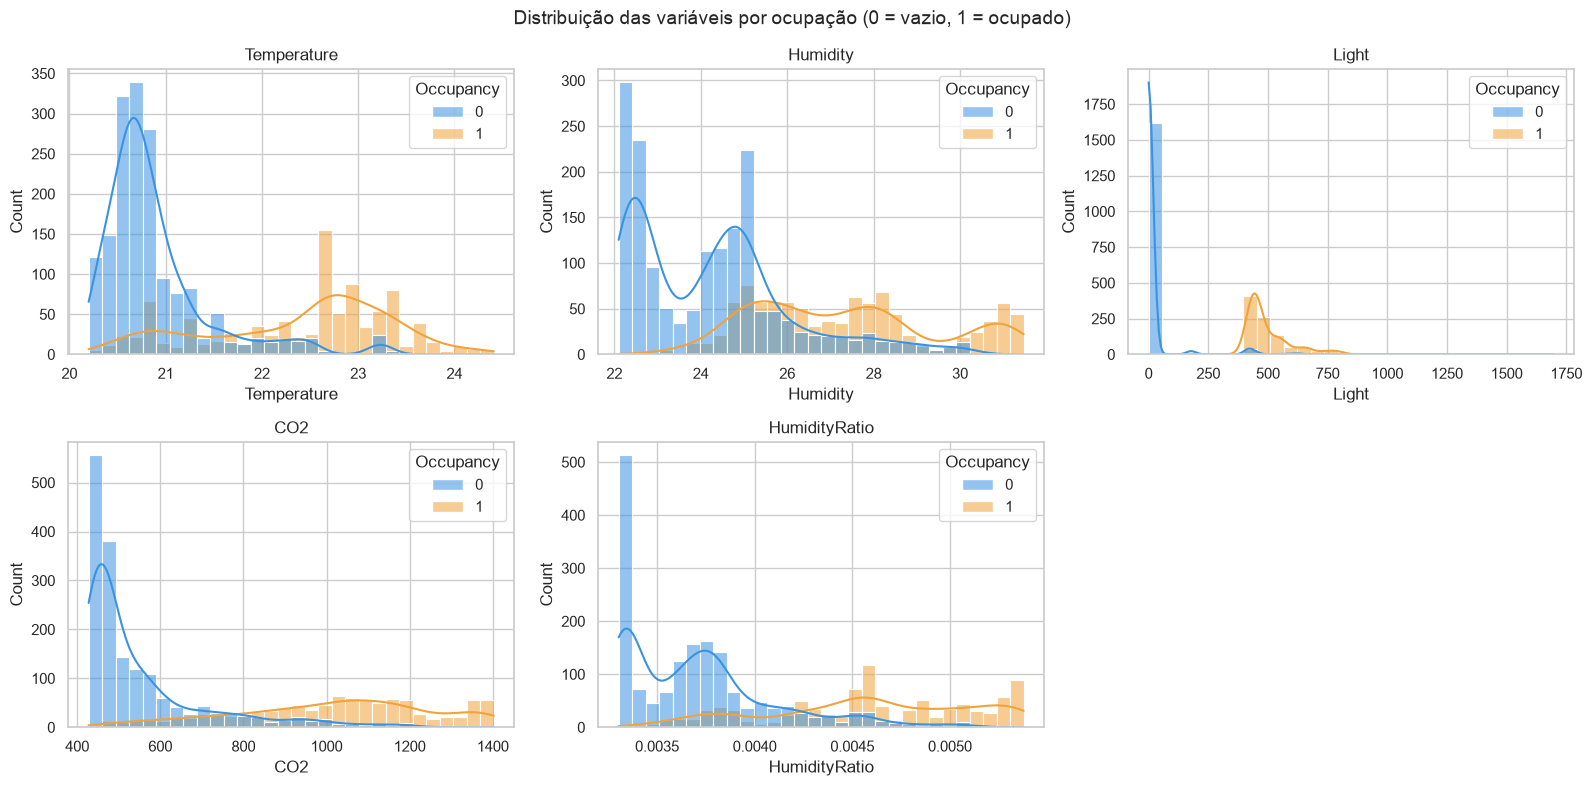

In [10]:
# Um histograma por variável, com as duas classes sobrepostas (azul = vazio, âmbar = ocupado).
# Se as duas cores aparecem em regiões diferentes do eixo X, a variável separa bem as classes.
# kde=True desenha a curva de densidade suavizada por cima das barras.
fig, eixos = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(eixos.flat, FEATURES):
    sns.histplot(data=df, x=col, hue=ALVO, bins=30, kde=True, ax=ax,
                 palette={0: "#3A93E0", 1: "#F2A23A"}, alpha=0.55)
    ax.set_title(col)

# São 5 variáveis numa grade de 6 espaços: o último quadro fica vazio e é escondido
eixos.flat[-1].axis("off")
plt.suptitle("Distribuição das variáveis por ocupação (0 = vazio, 1 = ocupado)", fontsize=14)
plt.tight_layout()
plt.show()

### Gráfico 2: proporção das classes da variável alvo

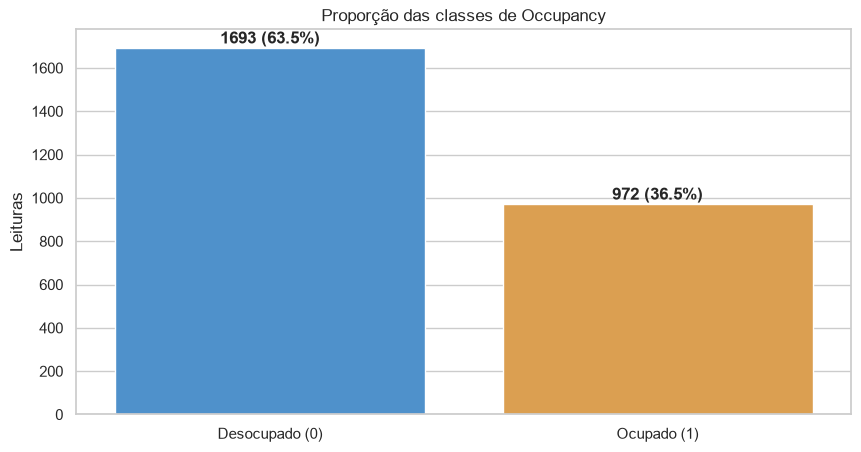

In [11]:
# Conta quantas leituras existem de cada classe (0 = desocupado, 1 = ocupado).
# Classes muito desiguais exigiriam cuidado extra; aqui o desequilíbrio é moderado.
contagem = df[ALVO].value_counts().sort_index()
rotulos = ["Desocupado (0)", "Ocupado (1)"]
ax = sns.barplot(x=rotulos, y=contagem.values, hue=rotulos, palette=["#3A93E0", "#F2A23A"], legend=False)

# Escreve sobre cada barra a quantidade absoluta e o percentual do total
for i, v in enumerate(contagem.values):
    ax.text(i, v + 20, f"{v} ({v / len(df):.1%})", ha="center", fontweight="bold")
ax.set_title("Proporção das classes de Occupancy")
ax.set_ylabel("Leituras")
plt.show()

### Gráfico 3: mapa de calor da correlação de Pearson

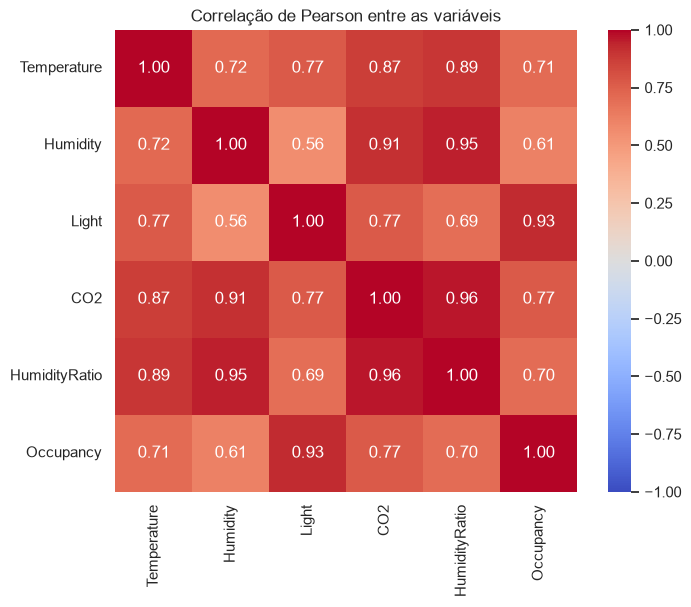

In [12]:
# A correlação de Pearson mede a relação linear entre duas variáveis, de -1 a +1.
# Perto de +1: sobem juntas; perto de -1: uma sobe quando a outra desce; perto de 0: sem relação linear.
# A última linha (Occupancy) mostra quais sensores mais acompanham a presença de pessoas.
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlação de Pearson entre as variáveis")
plt.show()

### Gráfico 4: luminosidade x CO₂, as duas variáveis mais ligadas à ocupação

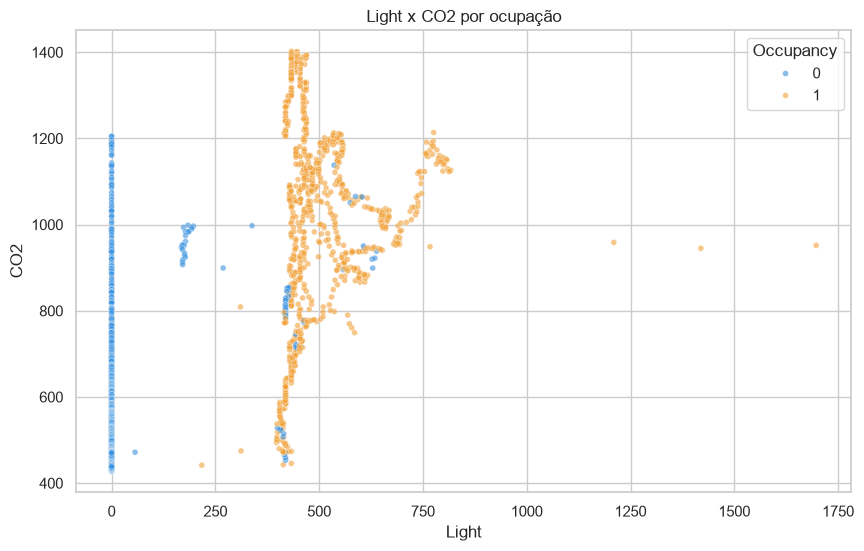

In [13]:
# Dispersão das duas variáveis mais correlacionadas com a ocupação.
# Cada ponto é uma leitura de 1 minuto; a cor indica se a sala estava ocupada.
# Regiões de uma cor só mostram onde um modelo consegue separar as classes com facilidade.
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="Light", y="CO2", hue=ALVO, palette={0: "#3A93E0", 1: "#F2A23A"}, alpha=0.6, s=18)
plt.title("Light x CO2 por ocupação")
plt.show()

### Análise da Fase 1

**Estrutura.** São 2.665 leituras e, após descartar `date`, 5 variáveis preditoras numéricas (`float64`) e o alvo `Occupancy` (`int64`). Não há colunas de texto para codificar.

**Classes.** 1.693 leituras com a sala vazia (63,5%) e 972 ocupada (36,5%). O desbalanceamento é moderado: não exige reamostragem, mas justifica o `stratify=y` na divisão e olhar precisão e recall além da acurácia.

**Luminosidade é a variável dominante.** A correlação de `Light` com `Occupancy` é **0,93**, a mais alta da tabela. A mediana de `Light` é **0 lux**: na maior parte do tempo a sala está escura e vazia. O histograma mostra duas populações quase sem sobreposição: leituras baixas para sala vazia e acima de cerca de 400 lux para sala ocupada.

**CO₂ é o segundo sinal (0,77).** Pessoas respiram, e o CO₂ sobe de cerca de 450 ppm para 700 a 1.400 ppm com a sala ocupada. No gráfico de dispersão, as leituras ocupadas formam um bloco no canto de luz alta, e o CO₂ ajuda a separar os casos ambíguos, como a luz acesa sem ninguém ou a luz natural entrando pela janela.

**Multicolinearidade.** `Humidity`, `HumidityRatio` e `CO2` são fortemente correlacionadas entre si (0,91 a 0,96), porque a respiração humana libera CO₂ e vapor d'água ao mesmo tempo. Para uma Árvore de Decisão isso não é problema (ela escolhe a variável que mais separa e ignora as redundantes). Para o KNN, que mede distâncias, as variáveis redundantes pesam mais e as escalas muito diferentes (`Light` vai até 1.697 enquanto `HumidityRatio` não passa de 0,006) exigem padronização.

**Estratégia de modelagem.** Os dados indicam que fronteiras simples do tipo "luz acima de X" devem acertar quase tudo, o que favorece a Árvore de Decisão: ela aprende exatamente esse tipo de regra e é explicável. O risco a vigiar é o modelo depender só da luz, por isso a Fase 6 compara configurações dos modelos também em dias que eles nunca viram.

<br>

# **Fase 2: Limpeza e Tratamento de Dados (Data Prep)**

> Remoção de duplicadas, verificação e imputação de ausentes com justificativa, e análise de outliers por boxplot.

### Linhas duplicadas

In [14]:
# -----------------------------------------------------------------------------
# Fase 2.1: remoção de linhas duplicadas
# -----------------------------------------------------------------------------
# duplicated() marca como True cada linha idêntica a uma linha anterior (todas as colunas iguais).
antes = len(df)
duplicadas = df.duplicated().sum()

# drop_duplicates() mantém a primeira ocorrência e remove as repetições.
# reset_index(drop=True) renumera as linhas de 0 em diante, sem buracos no índice.
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicadas encontradas: {duplicadas}")
print(f"Linhas antes: {antes} | depois: {len(df)}")

Duplicadas encontradas: 82
Linhas antes: 2665 | depois: 2583


Com a coluna `date` presente, nenhuma linha se repetia. Sem ela, **82 leituras** ficaram idênticas: minutos consecutivos em que os sensores não variaram (por exemplo, sala escura e estável de madrugada). Removê-las é importante para o modelo: se a mesma leitura cair uma vez no treino e outra no teste, o teste deixa de medir a capacidade de generalizar e vira uma prova com a resposta já vista, inflando a acurácia.

### Dados ausentes

In [15]:
# -----------------------------------------------------------------------------
# Fase 2.2: verificação de dados ausentes (NaN)
# -----------------------------------------------------------------------------
# isna() marca cada célula vazia como True; sum() conta quantas existem por coluna.
df.isna().sum()

Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64

A base não tem nenhum valor ausente. Para validar o pipeline de imputação, simulamos 2% de ausentes em cada variável numa **cópia** dos dados (a base de modelagem continua intacta) e escolhemos média ou mediana pela assimetria de cada distribuição.

In [16]:
# -----------------------------------------------------------------------------
# Fase 2.3: simulação de ausentes e imputação por média ou mediana
# -----------------------------------------------------------------------------
# Gerador aleatório com semente fixa: a simulação sai igual em toda execução
rng = np.random.default_rng(42)

# Trabalhamos numa CÓPIA: a base usada na modelagem não recebe nenhum valor inventado
df_simulado = df.copy()
for col in FEATURES:
    # Sorteia 2% das linhas (sem repetir) e apaga o valor dessa coluna nelas
    idx = rng.choice(len(df_simulado), size=int(0.02 * len(df_simulado)), replace=False)
    df_simulado.loc[idx, col] = np.nan
print("Ausentes simulados por coluna:")
print(df_simulado[FEATURES].isna().sum())

# skew() mede a assimetria: 0 é simétrica; positiva indica cauda longa à direita
assimetria = df[FEATURES].skew()
estrategia = {}
for col in FEATURES:
    # Regra usual: |skew| > 0,5 indica assimetria relevante. Nesse caso a média é puxada
    # pelos valores extremos, e a mediana representa melhor o valor típico.
    estrategia[col] = "mediana" if abs(assimetria[col]) > 0.5 else "média"
    valor = df_simulado[col].median() if estrategia[col] == "mediana" else df_simulado[col].mean()
    # fillna() preenche só as células vazias com o valor escolhido
    df_simulado[col] = df_simulado[col].fillna(valor)

# Tabela de apoio à decisão: assimetria, estratégia escolhida, média e mediana de cada variável
pd.DataFrame({"assimetria (skew)": assimetria.round(3), "estratégia": estrategia,
              "média": df[FEATURES].mean().round(4), "mediana": df[FEATURES].median().round(4)})

Ausentes simulados por coluna:
Temperature      51
Humidity         51
Light            51
CO2              51
HumidityRatio    51
dtype: int64


,assimetria (skew),estratégia,média,mediana
Temperature,0.801,mediana,21.4609,20.9725
Humidity,0.647,mediana,25.4168,25.0000
Light,0.711,mediana,199.3618,0.0000
CO2,0.744,mediana,725.8475,594.2500
HumidityRatio,0.614,mediana,0.0040,0.0038


In [17]:
# Conferência da imputação: não pode sobrar nenhum vazio...
print("Ausentes após a imputação:", int(df_simulado.isna().sum().sum()))

# ...e a média de cada variável não deve mudar muito. Uma mudança grande indicaria
# que o preenchimento distorceu a distribuição original.
print("Diferença máxima entre as médias antes e depois (em % da média original):")
print(((df_simulado[FEATURES].mean() - df[FEATURES].mean()).abs() / df[FEATURES].mean() * 100).round(3))

Ausentes após a imputação: 0
Diferença máxima entre as médias antes e depois (em % da média original):
Temperature      0.044
Humidity         0.087
Light            1.847
CO2              0.291
HumidityRatio    0.121
dtype: float64


**Justificativa da escolha.** As 5 variáveis têm assimetria positiva entre 0,61 e 0,80 (cauda longa à direita). O caso mais claro é `Light`: a mediana é 0 lux e a média passa de 190, puxada pelas horas de expediente. Em distribuições assim, a média é arrastada pela cauda e imputaria um valor que quase nunca acontece. Já a **mediana** representa o valor típico e não é afetada por extremos, por isso foi a escolhida para todas as colunas. A verificação mostra que a imputação praticamente não altera as médias, ou seja, não distorce a distribuição.

### Outliers

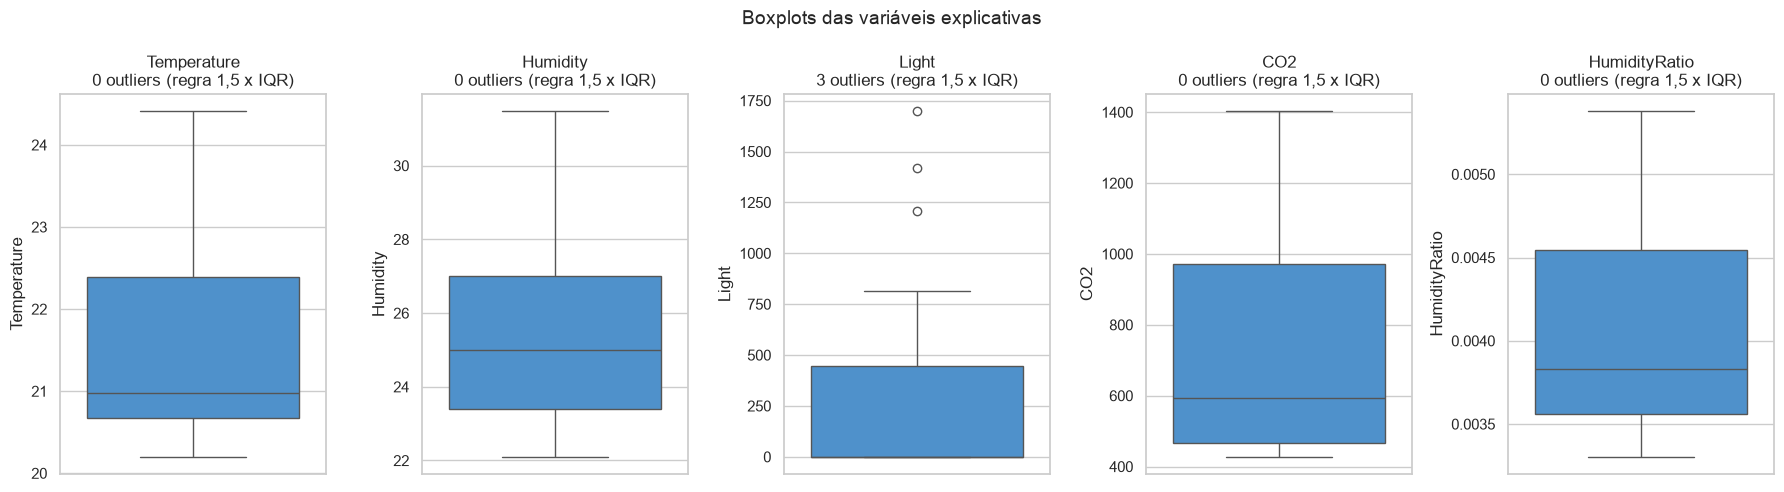

In [18]:
# -----------------------------------------------------------------------------
# Fase 2.4: identificação de outliers com boxplots
# -----------------------------------------------------------------------------
# O boxplot mostra a caixa entre o 1º quartil (Q1) e o 3º quartil (Q3), a mediana no meio
# e os "bigodes" até 1,5 x IQR (IQR = Q3 - Q1). Pontos além dos bigodes são outliers.
fig, eixos = plt.subplots(1, 5, figsize=(18, 5))
for ax, col in zip(eixos, FEATURES):
    sns.boxplot(y=df[col], ax=ax, color="#3A93E0")

    # Conta os outliers pela mesma regra do boxplot, para escrever no título do gráfico
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    ax.set_title(f"{col}\n{n_out} outliers (regra 1,5 x IQR)")
plt.suptitle("Boxplots das variáveis explicativas", fontsize=14)
plt.tight_layout()
plt.show()

**Análise.** Pela regra de 1,5 x IQR, só `Light` tem valores discrepantes (3 leituras acima de cerca de 1.100 lux). São fisicamente plausíveis: sol forte entrando pela janela ou luminária próxima ao sensor. `Temperature`, `Humidity`, `CO2` e `HumidityRatio` não têm outliers.

**Decisão: manter.** Não são erros de leitura, e sim situações reais que o sistema vai encontrar em operação. Além disso, a Árvore de Decisão é pouco sensível a outliers, porque divide por limiares e não por médias, e no KNN a padronização reduz o peso deles.

<br>

# **Fase 3: Feature Engineering**

> Criação de uma nova coluna numérica a partir de uma operação matemática entre colunas existentes.

### A nova variável: `razao_co2_luz = CO2 / (Light + 1)`

**Ideia.** Pessoas numa sala fazem duas coisas ao mesmo tempo: acendem a luz e elevam o CO₂ com a respiração. A razão entre CO₂ e luz resume essa relação num único número:

- **sala ocupada:** luz alta (centenas de lux) e CO₂ moderado, então a razão fica **pequena**;
- **sala vazia:** luz perto de zero e CO₂ no nível de fora, então a razão fica **grande**.

**Por que somar 1 à luz.** Na maior parte do tempo `Light` vale exatamente 0. Dividir por zero geraria valores infinitos; com `Light + 1` o denominador nunca é zero e a operação é sempre válida.

In [19]:
# -----------------------------------------------------------------------------
# Fase 3.1: garantia de que não há nulos nas colunas usadas no cálculo
# -----------------------------------------------------------------------------
# Uma operação com NaN gera NaN. Por isso a verificação vem ANTES de criar a coluna.
nulos_antes = df[["CO2", "Light"]].isna().sum()
print("Nulos em CO2 e Light antes do cálculo:")
print(nulos_antes)
assert nulos_antes.sum() == 0, "Há valores ausentes em CO2 ou Light: trate-os antes de criar a variável"

# -----------------------------------------------------------------------------
# Fase 3.2: criação da nova variável
# -----------------------------------------------------------------------------
# Light + 1 evita a divisão por zero nos momentos de sala escura (Light = 0)
df["razao_co2_luz"] = df["CO2"] / (df["Light"] + 1)

# -----------------------------------------------------------------------------
# Fase 3.3: validação do resultado
# -----------------------------------------------------------------------------
# A nova coluna não pode ter nulos nem infinitos (sinal de divisão por zero)
print()
print("Nulos na nova coluna:", int(df["razao_co2_luz"].isna().sum()))
print("Infinitos na nova coluna:", int(np.isinf(df["razao_co2_luz"]).sum()))
assert df["razao_co2_luz"].notna().all() and np.isfinite(df["razao_co2_luz"]).all()

df["razao_co2_luz"].describe().round(2)

Nulos em CO2 e Light antes do cálculo:
CO2      0
Light    0
dtype: int64

Nulos na nova coluna: 0
Infinitos na nova coluna: 0


count    2583.00
mean      319.91
std       284.76
min         0.56
25%         2.21
50%       439.75
75%       495.00
max      1205.25
Name: razao_co2_luz, dtype: float64

Mediana da razao_co2_luz por classe:
Occupancy
Desocupado    472.75
Ocupado         2.00
Name: razao_co2_luz, dtype: float64

Correlação com Occupancy:
razao_co2_luz   -0.867
Humidity         0.605
HumidityRatio    0.695
Temperature      0.700
CO2              0.764
Light            0.927
Name: Occupancy, dtype: float64


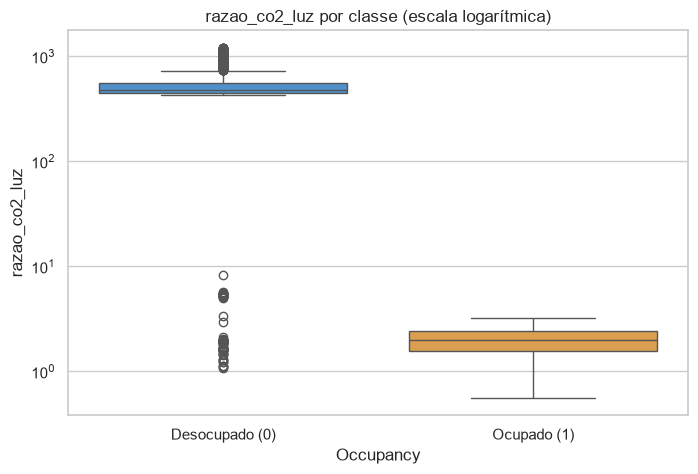

In [20]:
# Mediana da nova variável em cada classe: mostra o quanto ela separa sala vazia de ocupada
print("Mediana da razao_co2_luz por classe:")
print(df.groupby(ALVO)["razao_co2_luz"].median().round(2).rename({0: "Desocupado", 1: "Ocupado"}))
print()

# Correlação de Pearson da nova variável com o alvo, comparada à das variáveis originais
print("Correlação com Occupancy:")
print(df[FEATURES + ["razao_co2_luz", ALVO]].corr()[ALVO].drop(ALVO).round(3).sort_values())

# Boxplot por classe em escala logarítmica: a razão varia de menos de 1 a mais de 1.000,
# e o log permite ver as duas classes no mesmo gráfico
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x=ALVO, y="razao_co2_luz", hue=ALVO, palette={0: "#3A93E0", 1: "#F2A23A"}, legend=False, ax=ax)
ax.set_yscale("log")
ax.set_xticks([0, 1], ["Desocupado (0)", "Ocupado (1)"])
ax.set_title("razao_co2_luz por classe (escala logarítmica)")
plt.show()

### Análise da Fase 3

A nova variável foi criada sem nenhum nulo ou infinito e separa muito bem as classes: a mediana é de cerca de **473** com a sala vazia e de **2** com a sala ocupada. A correlação com `Occupancy` é de **-0,87**, a segunda mais forte da base em valor absoluto, atrás apenas de `Light`. O sinal negativo é esperado: quanto maior a razão, menor a chance de haver gente na sala.

Ela passa a fazer parte das variáveis preditoras dos dois modelos. Um ponto de atenção registrado aqui e verificado na Fase 7: quando a luz está apagada, a razão é praticamente o próprio valor do CO₂, que muda de um dia para outro. Por isso ela pode ser menos estável em dias diferentes dos usados no treino.

In [21]:
# Lista final de variáveis preditoras: as 5 originais mais a variável criada nesta fase
FEATURES_MODELO = FEATURES + ["razao_co2_luz"]
FEATURES_MODELO

['Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio', 'razao_co2_luz']

<br>

# **Fase 4: Divisão e Balanceamento dos Dados**

> Separação de X e y, divisão 80/20 estratificada com semente fixa e justificativa sobre data leakage.

In [22]:
# -----------------------------------------------------------------------------
# Fase 4: separação de X e y e divisão em treino e teste
# -----------------------------------------------------------------------------
# X: matriz de variáveis preditoras (o que o modelo enxerga)
# y: variável alvo (o que o modelo precisa acertar)
X = df[FEATURES_MODELO]
y = df[ALVO]

# test_size=0.2  -> 80% das leituras para treino e 20% para teste
# stratify=y     -> treino e teste ficam com a mesma proporção de salas ocupadas da base
# random_state=42 -> a divisão é sorteada sempre do mesmo jeito (reprodutibilidade)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Treino: {X_train.shape[0]} linhas | Teste: {X_test.shape[0]} linhas")

# Conferência da estratificação: as três colunas devem ter praticamente a mesma proporção
pd.DataFrame({
    "geral": y.value_counts(normalize=True),
    "treino": y_train.value_counts(normalize=True),
    "teste": y_test.value_counts(normalize=True),
}).round(4).rename(index={0: "Desocupado (0)", 1: "Ocupado (1)"})

Treino: 2066 linhas | Teste: 517 linhas


,geral,treino,teste
Occupancy,,,
Desocupado (0),0.6237,0.6239,0.6228
Ocupado (1),0.3763,0.3761,0.3772


O `stratify=y` manteve a mesma proporção de salas ocupadas (cerca de 37,7%) no conjunto geral, no treino e no teste, e o `random_state=42` garante que qualquer pessoa que rode este notebook obtenha exatamente a mesma divisão.

### Por que dividir antes de qualquer transformação (Data Leakage)

O conjunto de teste simula o futuro: dados que o modelo vai encontrar em produção e que ainda não existem no momento do treino. Qualquer transformação estatística, como padronização (média e desvio), normalização (mínimo e máximo) ou imputação pela mediana, calcula parâmetros a partir dos dados. Se esses parâmetros forem calculados na base inteira **antes** da divisão, informações do teste vazam para o treino: o modelo passa a "conhecer" a escala e a distribuição dos dados que deveria encontrar pela primeira vez.

O efeito é uma acurácia otimista no notebook e uma queda quando o modelo vai para a operação real. A ordem correta, aplicada na Fase 5 com o KNN, é:

1. dividir treino e teste;
2. ajustar o transformador (`fit`) **somente no treino**;
3. aplicar (`transform`) o mesmo transformador no teste e, depois, em produção.

O mesmo raciocínio justificou a remoção das duplicadas na Fase 2: uma leitura repetida dos dois lados da divisão também é um vazamento.

<br>

# **Fase 5: Escalonamento de Variáveis (StandardScaler)**

> StandardScaler apenas para o KNN, com `fit_transform()` no treino e `transform()` no teste. A Árvore de Decisão segue sem escalonamento.

### Por que o KNN precisa de escalonamento

O KNN decide pela **distância** entre leituras. Sem escalonamento, a luminosidade (0 a mais de 1.000 lux) e o CO₂ (400 a 1.400 ppm) dominariam a distância, e a temperatura (19 a 24 °C) ou a razão de umidade (0,003 a 0,006) praticamente não contariam. O `StandardScaler` coloca todas as variáveis na mesma régua: média 0 e desvio padrão 1.

A regra contra o vazamento de dados é obrigatória aqui: a média e o desvio são calculados **só com o treino** (`fit_transform`) e depois aplicados, sem recalcular, ao teste (`transform`).

In [23]:
# -----------------------------------------------------------------------------
# Fase 5.1: StandardScaler para o KNN
# -----------------------------------------------------------------------------
scaler = StandardScaler()

# fit_transform no TREINO: aprende a média e o desvio de cada variável e já transforma o treino
X_train_knn = scaler.fit_transform(X_train)

# transform no TESTE: usa a média e o desvio aprendidos no treino. Nunca fit no teste:
# isso seria deixar o teste influenciar o pré-processamento (data leakage).
X_test_knn = scaler.transform(X_test)

# Conferência: no treino, médias 0 e desvios 1. No teste, valores PRÓXIMOS (não exatos),
# justamente porque o teste foi transformado com os parâmetros do treino.
pd.DataFrame({
    "média aprendida (treino)": scaler.mean_,
    "desvio aprendido (treino)": scaler.scale_,
    "média treino escalado": X_train_knn.mean(axis=0),
    "desvio treino escalado": X_train_knn.std(axis=0),
    "média teste escalado": X_test_knn.mean(axis=0),
}, index=FEATURES_MODELO).round(4)

,média aprendida (treino),desvio aprendido (treino),média treino escalado,desvio treino escalado,média teste escalado
Temperature,21.4523,1.0240,-0.0,1.0,0.0417
Humidity,25.3982,2.4394,-0.0,1.0,0.0383
Light,199.0857,251.7758,0.0,1.0,0.0055
CO2,724.6075,292.1433,0.0,1.0,0.0212
HumidityRatio,0.0040,0.0006,0.0,1.0,0.0434
razao_co2_luz,321.2121,285.9734,0.0,1.0,-0.0227


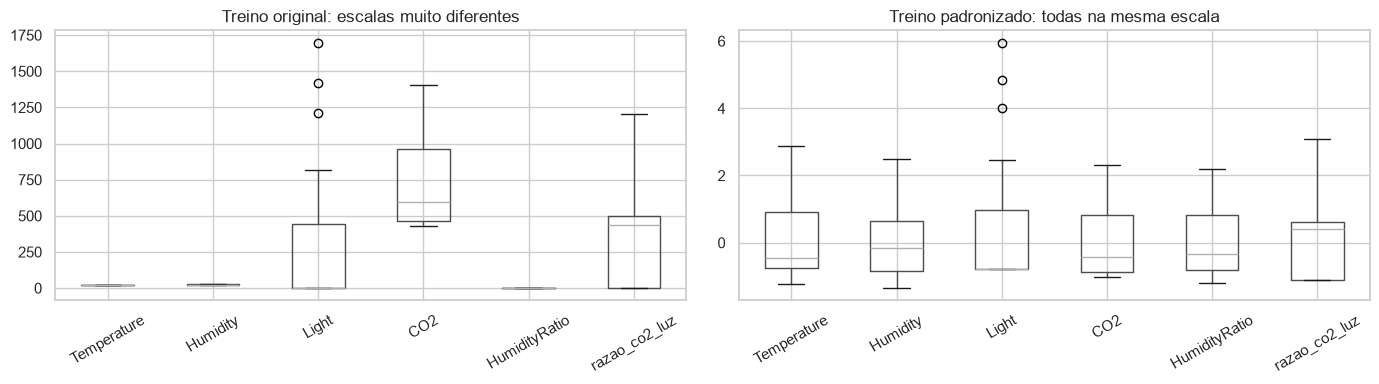

In [24]:
# -----------------------------------------------------------------------------
# Fase 5.2: dados da Árvore de Decisão SEM escalonamento
# -----------------------------------------------------------------------------
# A árvore recebe as variáveis nas unidades originais (lux, ppm, °C...).
# Ver a justificativa na célula de texto a seguir.
X_train_arvore = X_train
X_test_arvore = X_test

# Comparação visual da diferença de escala que o KNN enfrentaria sem o StandardScaler
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
X_train.boxplot(ax=eixos[0], rot=30)
eixos[0].set_title("Treino original: escalas muito diferentes")
pd.DataFrame(X_train_knn, columns=FEATURES_MODELO).boxplot(ax=eixos[1], rot=30)
eixos[1].set_title("Treino padronizado: todas na mesma escala")
plt.tight_layout()
plt.show()

### Por que a Árvore de Decisão dispensa o escalonamento

A árvore não mede distâncias. Em cada nó, ela faz uma pergunta sobre **uma variável de cada vez**, do tipo "`Light` ≤ 205 lux?", e escolhe o limiar que melhor separa as classes. Mudar a escala de uma variável, por exemplo de lux para milhares de lux, só move o limiar junto (de 205 para 0,205): a divisão das leituras e a decisão final são exatamente as mesmas.

Por isso a diferença entre a luminosidade (0 a mais de 1.000 lux) e a temperatura (19 a 24 °C) não afeta a árvore, e escalonar só acrescentaria uma etapa a mais para manter em produção. Manter as unidades originais tem ainda uma vantagem prática: as regras da árvore ficam legíveis para a equipe de manutenção, em lux e ppm.

<br>

# **Fase 6: Ajuste de Parâmetros e Combate ao Overfitting**

> KNN variando `n_neighbors` e Árvore de Decisão variando `max_depth`, com a acurácia registrada no treino e no teste.

### Como os hiperparâmetros foram avaliados

Para cada configuração registramos quatro números:

1. **Acurácia no treino:** quanto o modelo acerta nos dados que ele já viu.
2. **Acurácia no teste:** o desempenho nos 20% separados na Fase 4.
3. **Validação cruzada (5 partes) no treino:** o critério de **escolha**. O treino é dividido em 5 partes; o modelo treina em 4 e é avaliado na 5ª, girando 5 vezes. Assim a escolha não "espia" o teste, que fica reservado para a avaliação final da Fase 7.
4. **Acurácia em dias novos:** a UCI publica mais dois arquivos da mesma sala, gravados nos dias seguintes (04 a 18/02/2015), com 17.895 leituras que não participam de nenhuma etapa do treino. É o teste mais próximo da operação real.

**Overfitting** aparece quando o treino fica muito acima dos demais: o modelo decorou os dados em vez de aprender o padrão.

In [25]:
# -----------------------------------------------------------------------------
# Fase 6.1: dias novos, preparados com exatamente o mesmo pipeline
# -----------------------------------------------------------------------------
# datatraining.txt e datatest2.txt vieram no mesmo zip da UCI, extraídos em data/raw.
# Recebem a mesma engenharia de variáveis da Fase 3 e, para o KNN, a escala do treino (transform).
def preparar_dias_novos(caminho):
    d = pd.read_csv(caminho).drop(columns=["date"])
    d["razao_co2_luz"] = d["CO2"] / (d["Light"] + 1)
    return d

novos = pd.concat([preparar_dias_novos("data/raw/datatraining.txt"),
                   preparar_dias_novos("data/raw/datatest2.txt")], ignore_index=True)
X_novos = novos[FEATURES_MODELO]
y_novos = novos[ALVO]
X_novos_knn = scaler.transform(X_novos)   # mesma escala aprendida no treino
print(f"Leituras de dias novos: {len(novos)}")

# Validação cruzada estratificada e reprodutível, usada nas duas buscas a seguir
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Leituras de dias novos: 17895


In [26]:
# -----------------------------------------------------------------------------
# Fase 6.2: KNN variando o número de vizinhos K
# -----------------------------------------------------------------------------
# Valores ímpares evitam empate na votação entre as duas classes.
resultados_knn = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    modelo = KNeighborsClassifier(n_neighbors=k)
    modelo.fit(X_train_knn, y_train)

    # Na validação cruzada o StandardScaler vai dentro de um pipeline: em cada rodada ele é
    # ajustado só nas 4 partes de treino, sem vazar informação para a parte de validação.
    cv_media = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)),
                               X_train, y_train, cv=cv).mean()

    resultados_knn.append({
        "K": k,
        "acurácia treino": accuracy_score(y_train, modelo.predict(X_train_knn)),
        "acurácia teste": accuracy_score(y_test, modelo.predict(X_test_knn)),
        "validação cruzada": cv_media,
        "dias novos": accuracy_score(y_novos, modelo.predict(X_novos_knn)),
    })
tabela_knn = pd.DataFrame(resultados_knn).set_index("K")
tabela_knn.style.format("{:.2%}").highlight_max(subset=["validação cruzada"], color="#cfe8ff")

,acurácia treino,acurácia teste,validação cruzada,dias novos
K,,,,
1,100.00%,99.42%,98.74%,86.19%
3,99.27%,99.03%,98.74%,86.82%
5,99.08%,98.84%,98.79%,88.87%
7,98.98%,98.65%,98.06%,88.10%
9,98.40%,98.84%,98.02%,89.01%
11,98.40%,98.84%,97.87%,89.00%
15,97.82%,98.45%,97.73%,89.34%


In [27]:
# -----------------------------------------------------------------------------
# Fase 6.3: Árvore de Decisão variando a profundidade máxima
# -----------------------------------------------------------------------------
# max_depth=None deixa a árvore crescer até separar todas as leituras de treino.
resultados_arvore = []
for prof in [2, 3, 4, 5, 7, None]:
    modelo = DecisionTreeClassifier(max_depth=prof, random_state=42)
    modelo.fit(X_train_arvore, y_train)
    cv_media = cross_val_score(DecisionTreeClassifier(max_depth=prof, random_state=42),
                               X_train_arvore, y_train, cv=cv).mean()
    resultados_arvore.append({
        "max_depth": "None" if prof is None else prof,
        "folhas": modelo.get_n_leaves(),
        "acurácia treino": accuracy_score(y_train, modelo.predict(X_train_arvore)),
        "acurácia teste": accuracy_score(y_test, modelo.predict(X_test_arvore)),
        "validação cruzada": cv_media,
        "dias novos": accuracy_score(y_novos, modelo.predict(X_novos)),
    })
tabela_arvore = pd.DataFrame(resultados_arvore).set_index("max_depth")
tabela_arvore.style.format({c: "{:.2%}" for c in tabela_arvore.columns if c != "folhas"}).highlight_max(
    subset=["validação cruzada"], color="#cfe8ff")

,folhas,acurácia treino,acurácia teste,validação cruzada,dias novos
max_depth,,,,,
2,3,97.77%,98.07%,97.68%,95.75%
3,5,97.77%,98.07%,97.68%,95.75%
4,9,98.40%,99.03%,97.87%,95.67%
5,14,98.60%,99.23%,97.82%,95.46%
7,24,99.13%,99.42%,97.63%,94.81%
None,36,100.00%,99.03%,97.53%,93.24%


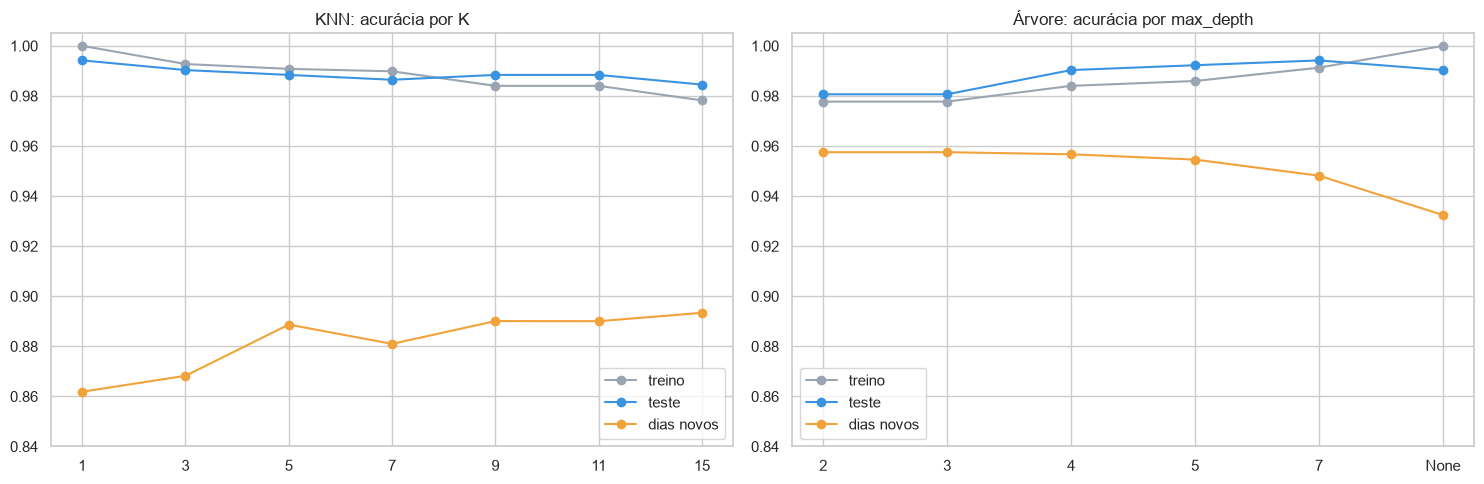

In [28]:
# Gráficos de treino x teste x dias novos: a distância entre as linhas revela o overfitting
fig, eixos = plt.subplots(1, 2, figsize=(15, 5))
for ax, tabela, nome in [(eixos[0], tabela_knn, "KNN: acurácia por K"),
                         (eixos[1], tabela_arvore, "Árvore: acurácia por max_depth")]:
    x = [str(i) for i in tabela.index]
    ax.plot(x, tabela["acurácia treino"], "o-", label="treino", color="#9AA5B1")
    ax.plot(x, tabela["acurácia teste"], "o-", label="teste", color="#3A93E0")
    ax.plot(x, tabela["dias novos"], "o-", label="dias novos", color="#F2A23A")
    ax.set_title(nome)
    ax.set_ylim(0.84, 1.005)
    ax.legend()
plt.tight_layout()
plt.show()

### Onde ocorreu overfitting e qual configuração foi mais estável

**KNN.** Com **K = 1**, a acurácia de treino é de **100%**: cada leitura de treino é a vizinha mais próxima de si mesma, então o modelo apenas decora a base. O teste até parece ótimo (99,42%), porque vem dos mesmos três dias do treino, mas nos dias novos o K = 1 é o pior KNN (86,2%). Aumentar o K suaviza a decisão e reduz a diferença entre treino e teste. A validação cruzada aponta **K = 5** como a melhor configuração (98,79%), com treino de 99,08% e teste de 98,84%, uma diferença pequena.

**Árvore de Decisão.** Com **max_depth = None**, a árvore cresce até 36 folhas e chega a **100% no treino**, mas cai para 99,03% no teste e para **93,2% nos dias novos**, a pior de todas: é o sinal clássico de overfitting. As árvores rasas (2 a 4 níveis) têm treino e teste praticamente iguais e são as mais estáveis em dias novos (95,7%). A validação cruzada aponta **max_depth = 4** como a melhor configuração (97,87%), com 9 folhas, treino de 98,40% e teste de 99,03%.

**Conclusão da fase.** As configurações escolhidas para a avaliação final, pela validação cruzada e sem usar o teste, são **KNN com K = 5** e **Árvore com max_depth = 4**. Um detalhe que a tabela deixa claro: o conjunto de teste, por vir dos mesmos dias do treino, é otimista para todos os modelos. Os dias novos mostram a diferença real entre eles.